# Catch-Up Sleep and Depressive Symptoms
## INFO 2950 Project — Phase II
**Eric Wang and Mary Yang**

## Research Question
Among adults in NHANES 2017–2018 who usually sleep fewer than seven hours on workdays, is catch-up sleep duration (non-workday minus workday sleep duration) associated with depressive symptom scores?

## Data Collection and Cleaning

### Data Collection
We downloaded three public NHANES 2017–2018 datasets from the CDC website on October 15, 2026:

- Sleep Disorders (SLQ_J): usual sleep duration on weekdays/workdays (SLD012) and weekends/non-workdays (SLD013).
- Depression Screener (DPQ_J): nine depressive symptom items (DPQ010–DPQ090).
- Demographics (DEMO_J): participant age, sex, survey weights, and survey design variables.

The original SAS transport (.xpt) files are stored in data/raw and are preserved without modification. We use SEQN, the participant identifier, to merge the datasets.

Documentation:
- Sleep: https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/SLQ_J.htm
- Depression: https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DPQ_J.htm
- Demographics: https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm

### Cleaning Procedure
We check that SEQN is unique and nonmissing in each file, then merge the datasets using the sleep dataset as the starting sample.

For the nine depression items, responses other than 0–3 are treated as missing, including refused (7) and don't know (9). We calculate a total score from 0 to 27 only when all nine items are available.

We retain adults aged 18 or older with exact reported sleep durations in both variables. We exclude sleep codes 2 and 14 because they represent intervals rather than exact durations. We then restrict the sample to participants sleeping fewer than seven hours on workdays and having a complete depression score.

Catch-up sleep is calculated as non-workday minus workday sleep duration, in hours. Negative values are retained because they indicate less sleep on non-workdays. We save intermediate datasets and record the sample size after each filtering step.

In [28]:
import numpy as np
import pandas as pd
import duckdb

sleep = pd.read_sas("data/raw/SLQ_J.xpt", format="xport")
depression = pd.read_sas("data/raw/DPQ_J.xpt", format="xport")
demographics = pd.read_sas("data/raw/DEMO_J.xpt", format="xport")

for table in [sleep, depression, demographics]:
    assert table["SEQN"].notna().all(), "Missing SEQN"
    assert table["SEQN"].is_unique, "Duplicate SEQN"

df = duckdb.sql("""
    SELECT
        s.SEQN, s.SLD012, s.SLD013,
        m.RIDAGEYR, m.RIAGENDR,
        m.WTMEC2YR, m.SDMVPSU, m.SDMVSTRA,
        d.DPQ010, d.DPQ020, d.DPQ030,
        d.DPQ040, d.DPQ050, d.DPQ060,
        d.DPQ070, d.DPQ080, d.DPQ090
    FROM sleep AS s
    LEFT JOIN depression AS d ON s.SEQN = d.SEQN
    LEFT JOIN demographics AS m ON s.SEQN = m.SEQN
""").df()
df.to_csv("data/processed/01_merged.csv", index=False)
counts = {"Merged sleep sample": len(df)}

items = [
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]

df[items] = df[items].mask(df[items].abs() < 1e-12, 0)
df[items] = df[items].where(df[items].isin([0, 1, 2, 3]))

df = duckdb.sql("""
    SELECT *,
        DPQ010 + DPQ020 + DPQ030 + DPQ040 + DPQ050
        + DPQ060 + DPQ070 + DPQ080 + DPQ090 AS depression_score
    FROM df
""").df()
df.to_csv("data/processed/02_recoded.csv", index=False)

filters = [
    ("Adults aged 18+", "RIDAGEYR >= 18"),
    ("Exact sleep durations available",
     "SLD012 BETWEEN 3 AND 13.5 AND SLD013 BETWEEN 3 AND 13.5"),
    ("Workday sleep below 7 hours", "SLD012 < 7"),
    ("Complete depression score", "depression_score IS NOT NULL")
]
for label, condition in filters:
    df = duckdb.sql(f"SELECT * FROM df WHERE {condition}").df()
    counts[label] = len(df)

df = duckdb.sql("""
    SELECT *, SLD013 - SLD012 AS catch_up_sleep
    FROM df
""").df()
df.to_csv("data/processed/03_analysis_ready.csv", index=False)

sample_counts = pd.Series(counts, name="Participants").to_frame()
sample_counts.to_csv("data/processed/sample_counts.csv")
print(sample_counts)
print(df.head())

                                 Participants
Merged sleep sample                      6161
Adults aged 18+                          5856
Exact sleep durations available          5726
Workday sleep below 7 hours              1402
Complete depression score                1252
      SEQN  SLD012  SLD013  RIDAGEYR  RIAGENDR       WTMEC2YR  SDMVPSU  \
0  93713.0     5.5     7.0      67.0       1.0  166841.660681      1.0   
1  93715.0     5.0     5.0      71.0       1.0    9250.904672      2.0   
2  93722.0     6.0     7.0      60.0       2.0  126309.823276      1.0   
3  93723.0     6.0     7.0      64.0       1.0  229129.236930      1.0   
4  93728.0     6.5     8.0      53.0       1.0   31532.904509      1.0   

   SDMVSTRA  DPQ010  DPQ020  DPQ030  DPQ040  DPQ050  DPQ060  DPQ070  DPQ080  \
0     140.0     1.0     1.0     2.0     0.0     1.0     1.0     2.0     0.0   
1     139.0     0.0     0.0     3.0     1.0     0.0     0.0     0.0     0.0   
2     139.0     0.0     0.0     1.0     0.

## Data Description

Our analysis-ready dataset contains 1,252 rows and 19 columns. Each row represents a NHANES 2017–2018 participant aged 18 or older who reported fewer than seven hours of workday sleep, had usable workday and non-workday sleep durations, and provided complete responses to nine depression symptom questions. We created this dataset to examine whether catch-up sleep duration is associated with depressive symptom scores.

### Variables

| Columns | Description |
|---|---|
| SEQN | Unique participant identifier |
| SLD012, SLD013 | Usual workday and non-workday sleep duration, in hours |
| catch_up_sleep | Non-workday minus workday sleep duration, in hours |
| DPQ010–DPQ090 | Nine items measuring depressive symptom frequency over the past two weeks, each scored 0–3 |
| depression_score | Sum of all nine items, with a possible range of 0–27; higher scores indicate more reported symptoms |
| RIDAGEYR, RIAGENDR | Age and recorded sex |
| WTMEC2YR, SDMVPSU, SDMVSTRA | Examination weight, sampling unit, and stratum |

### Sources and Collection

NHANES was created by CDC/NCHS to assess the health and nutritional status of the U.S. civilian noninstitutionalized population. Participants received information about the survey’s purposes, procedures, and confidentiality through its informed-consent process. Our project uses publicly released data; we did not recruit or contact participants.

We downloaded three official SAS transport (.xpt) files: Sleep Disorders (SLQ_J), Depression Screener (DPQ_J), and Demographics (DEMO_J). Sleep questions were administered during household interviews, while depression questions were administered at the examination center.

### Preprocessing and Sample Selection

Using pandas and DuckDB, we checked that SEQN was unique and nonmissing in each file, then merged the datasets using the sleep dataset as the starting sample. We corrected near-zero numerical representations of zero symptom scores and treated responses outside 0–3 as missing. Depression totals were calculated only when all nine responses were valid.

We retained adults with workday sleep below seven hours and complete depression scores. We excluded missing sleep durations and codes 2 and 14, which represent less than three hours and at least fourteen hours rather than specific durations. Catch-up sleep was calculated as SLD013 minus SLD012, retaining negative differences. Original files were preserved, and intermediate datasets and sample counts were saved.

Survey sampling, voluntary participation, questionnaire eligibility, and nonresponse influence which observations are available. Participants requiring proxy responses were ineligible for the depression questionnaire. Our additional exclusions further restrict the final sample, which should not automatically be treated as representative of all U.S. adults.

### Data Access and Documentation

Raw data: [Original NHANES 2017–2018 data files](https://github.com/EricWangXX/INFO-2950-Project/tree/main/data/raw).

Official documentation: [NHANES overview](https://www.cdc.gov/nchs/nhanes/about/), [2017–2018 consent documents](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/documents.aspx?BeginYear=2017), [SLQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/SLQ_J.htm), [DPQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DPQ_J.htm), and [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm).

## Data Limitations

- These cross-sectional, observational data show associations, not causation. Depressive symptoms may also influence sleep.
- Sleep durations are self-reported and rounded to half-hour increments, introducing measurement error.
- The depression score includes a sleep-related item (DPQ030), creating potential overlap between the predictor and outcome.
- Excluding missing responses and bottom- or top-coded sleep durations may introduce selection bias.
- Work schedules, socioeconomic conditions, and health conditions may confound the association.
- The data come from 2017–2018 and may not reflect current patterns. Our unweighted summaries describe the selected sample, not national population estimates.

## Exploratory Data Analysis

We examined the 1,252 participants in the corrected analysis-ready dataset. All summaries are unweighted.

| Variable | Mean | Median | SD | Range |
|---|---:|---:|---:|---:|
| Workday sleep (hours) | 5.62 | 6.00 | 0.89 | 3–6.5 |
| Non-workday sleep (hours) | 7.20 | 7.00 | 1.92 | 3–13.5 |
| Catch-up sleep (hours) | 1.59 | 1.00 | 1.91 | −3.5–9 |
| Depression score | 3.54 | 2.00 | 4.41 | 0–23 |

On non-workdays, 794 participants reported longer sleep, 377 reported equal sleep, and 81 reported shorter sleep. Negative catch-up values were retained.

Depression scores were generally low: 382 participants scored zero. The mean exceeding the median suggests right skew. These descriptive results alone do not establish an association between catch-up sleep and depressive symptoms.

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "SLD012", "SLD013",
    "catch_up_sleep", "depression_score"
]
df[columns].describe().round(2)

,SLD012,SLD013,catch_up_sleep,depression_score
count,1252.00,1252.00,1252.00,1252.00
mean,5.62,7.20,1.59,3.54
std,0.89,1.92,1.91,4.41
min,3.00,3.00,-3.50,0.00
25%,5.00,6.00,0.00,0.00
50%,6.00,7.00,1.00,2.00
75%,6.50,8.50,3.00,5.00
max,6.50,13.50,9.00,23.00


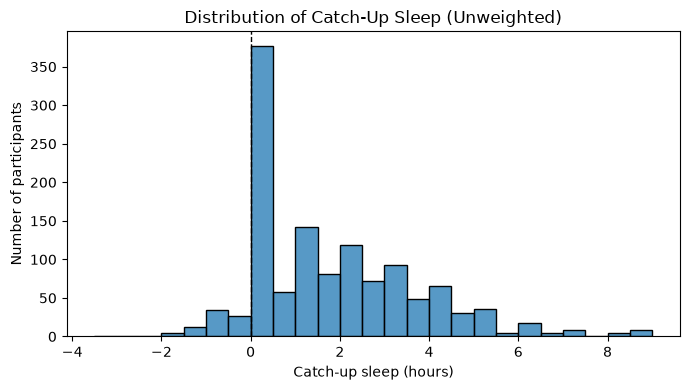

In [30]:
# Describe the distribution of catch-up sleep
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="catch_up_sleep", binwidth=0.5)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Catch-up sleep (hours)")
plt.ylabel("Number of participants")
plt.title("Distribution of Catch-Up Sleep (Unweighted)")
plt.tight_layout()
plt.show()

This histogram shows how sleep duration differs between workdays and non-workdays. Of the 1,252 participants, 794 reported longer non-workday sleep, 377 reported equal durations, and 81 reported shorter non-workday sleep. We retain negative differences as valid observations rather than treating them as errors.

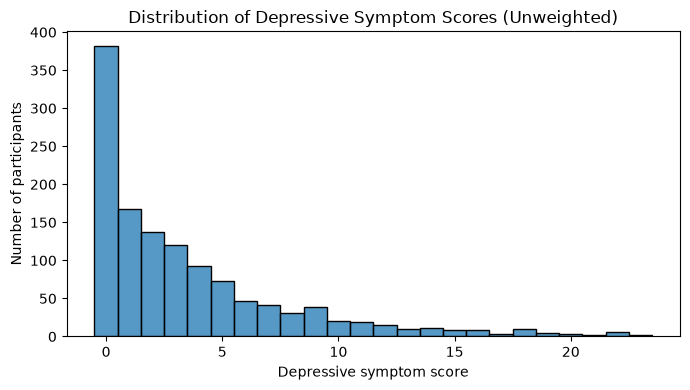

In [31]:
# Describe the distribution of depressive symptom scores
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="depression_score", discrete=True)
plt.xlabel("Depressive symptom score")
plt.ylabel("Number of participants")
plt.title("Distribution of Depressive Symptom Scores (Unweighted)")
plt.tight_layout()
plt.show()

Depressive symptom scores are concentrated at the lower end: 382 participants scored zero, and the median score is 2. The mean of 3.54 exceeds the median, consistent with a right-skewed distribution. The total is a symptom-screening score, not an independent clinical diagnosis.

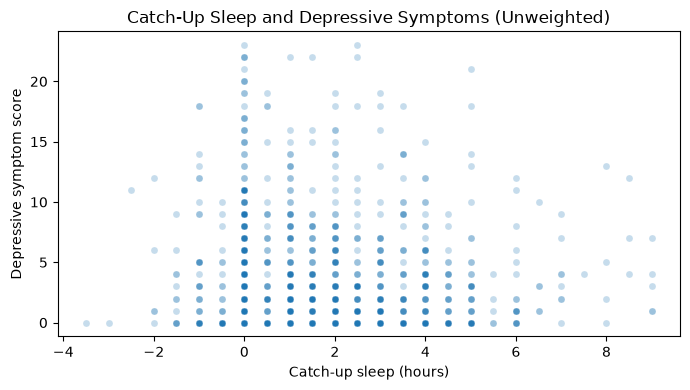

In [32]:
# Explore the relationship without fitting a regression model
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x="catch_up_sleep",
    y="depression_score",
    alpha=0.25,
    s=25
)
plt.xlabel("Catch-up sleep (hours)")
plt.ylabel("Depressive symptom score")
plt.title("Catch-Up Sleep and Depressive Symptoms (Unweighted)")
plt.tight_layout()
plt.show()

This scatterplot explores the relationship between catch-up sleep and depressive symptom scores. Transparency helps reveal overlapping observations, although the discrete scores and half-hour sleep measurements still produce overlap. This unadjusted visualization does not account for age, sex, or workday sleep duration and cannot establish causation.

## Questions for Reviewers

1. Is excluding bottom- and top-coded sleep durations appropriate?
2. Should we add a sensitivity analysis excluding the sleep-related depression item, DPQ030?
3. Are age, sex, and workday sleep duration sufficient initial adjustment variables, or is another confounder essential?
4. Should we implement survey-weighted analysis, or limit our conclusions to the observed sample?

## Preregistration Statement 1

**Hypothesis:** Among adults reporting fewer than seven hours of workday sleep, longer catch-up sleep duration is associated with lower depressive symptom scores.

**Proposed analysis:** We will fit a multiple linear regression predicting depression_score from catch_up_sleep, adjusting for age, sex, and workday sleep duration. We will examine the sign and magnitude of the catch_up_sleep coefficient; our hypothesis predicts a negative coefficient.

## Preregistration Statement 2

**Hypothesis:** The association between catch-up sleep duration and depressive symptom scores differs by sex.

**Proposed analysis:** We will fit separate multiple linear regressions for male and female participants, predicting depression_score from catch_up_sleep and adjusting for age and workday sleep duration. We will descriptively compare the catch_up_sleep coefficients across groups. Differences in estimated coefficients alone will not establish a statistically significant difference.

We will report both analyses in our final report regardless of whether the results support our hypotheses.

## Questions for Reviewers

1. Are age, sex, and workday sleep duration appropriate adjustment variables?
2. Is comparing separate regressions by sex appropriate for our research question and the methods covered in this course?
3. Should we incorporate NHANES survey weights, or limit our conclusions to the analyzed sample?